## M1b dense: $\alpha=1.0$ with Gaussian noise

Paper figures 11. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if RUN_EXPERIMENTS:
    import os
    import sys
    _active_env_bin = os.path.dirname(sys.executable)
    os.environ['PATH'] = _active_env_bin + os.pathsep + os.environ.get('PATH', '')
    _active_r_home = os.path.join(sys.prefix, 'lib', 'R')
    if os.path.isdir(_active_r_home):
        os.environ['R_HOME'] = _active_r_home
    from WERM.signal_priors import SparseGaussianSignal, SparseDiffSignal
    import WERM.model
    import WERM.performance_measures
    import importlib
    import WERM.comparison
    importlib.reload(WERM.comparison)
    import WERM.estimators
    from WERM.config import η_to_ψ
    import numpy as np
    import jax.numpy as jnp
    import jax
    jax.config.update('jax_enable_x64', True)
    import numpy.random as nprandom
    import matplotlib.pyplot as plt
    plt.switch_backend('module://matplotlib_inline.backend_inline')
    from functools import partial
    from tqdm.auto import tqdm
    from WERM.experiment_utils import data_hash as _data_hash, evaluate_changepoints as _evaluate_changepoints, summarize_setting as _summarize_setting, trial_rng as _trial_rng, weighted_erm_joint_cv as _weighted_erm_joint_cv
    import time
    from joblib import Parallel, delayed
    import sys
    import pickle
    import os
    os.environ['JAX_ENABLE_X64'] = 'True'
    random_seed = 46

    def run_single_trial(params, p, L, fixed_noise_scale, fractional_chgpt_locations, M, gamma_candidates, method_configs):
        """
        Executes a single simulation trial for a given delta, running multiple methods.
        This function is designed to be called in parallel by joblib.
        """
        (i, delta, j) = params
        rng = _trial_rng('M1b-alpha-1.0-gaussian', i, j)
        n = int(delta * p)
        true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)
        κ = 1.0
        α = 1.0
        σ_l_arr = κ * np.sqrt(delta) * np.ones(L)
        signal_prior = SparseGaussianSignal(α, delta, σ_l_arr)
        B̃ = signal_prior.sample(p, rng=rng)
        X = rng.normal(0, np.sqrt(1 / n), (n, p))
        epsilon = rng.normal(0.0, fixed_noise_scale, size=n)
        ε = epsilon
        X = X @ np.linalg.cholesky(Sigma).T
        true_chgpts = true_chgpt_locations_fn(n)
        C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)
        X_scaled = X * np.sqrt(n)
        B̃_scaled = B̃ / np.sqrt(n)
        Θ = X_scaled @ B̃_scaled
        y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
        y_standardized = np.array(y / np.std(y))
        trial_results = {'data_hash': _data_hash(X, y)}
        methods_status = {method_name: False for method_name in method_configs.keys()}
        for (method_name, method_func_info) in method_configs.items():
            try:
                method_start = time.time()
                cp = np.array([])
                if method_name == 'McScan':
                    cp = np.asarray(WERM.comparison.run_mcscan(np.array(X_scaled), y_standardized.flatten(), num_chgpts=None, method='auto'))
                    cp = np.array([c for c in cp if c != -1], dtype=int)
                elif method_name.startswith('WERM-unp-'):
                    num_cv_folds = int(method_name.rsplit('-', 1)[1].replace('fold', ''))
                    ((best_segments, _), cp) = _weighted_erm_joint_cv(X=X_scaled, y=y_standardized, M=M, M_scorer=M_scorer, Lmax=L, delta_fraction=1 / 20, l1_constants=(0.0,), num_folds=num_cv_folds, n_jobs=1, standardize_y=False, selection_strategy='exhaustive', penalty_norm='none', coefficient_loss='least_squares', coefficient_solver_options={'tol': 1e-05, 'max_iter': 50000})
                else:
                    continue
                method_time = time.time() - method_start
                evaluation = _evaluate_changepoints(cp, true_chgpts, n)
                raw_cp = evaluation['raw_cp']
                trial_results[f'runtime_{method_name}'] = method_time
                trial_results[f'raw_cp_{method_name}'] = None if raw_cp is None else raw_cp.copy()
                trial_results[f'status_{method_name}'] = evaluation['status']
                haus_value = evaluation['haus']
                if evaluation['status'] == 'empty_estimate':
                    haus_value = np.nan
                trial_results[f'haus_{method_name}'] = haus_value
                trial_results[f'size_{method_name}'] = evaluation['size']
                trial_results[f'chgpts_{method_name}'] = np.array([]) if raw_cp is None else raw_cp.copy()
                methods_status[method_name] = evaluation['status'] != 'not_applicable'
            except Exception as e:
                raise
        trial_results['n'] = n
        trial_results['true_chgpts'] = true_chgpts.copy()
        trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
        trial_results['methods_status'] = methods_status
        return (i, j, trial_results)
    p = 200
    L = 4
    fixed_noise_scale = np.sqrt(0.1)
    delta_list = np.arange(2.0, 10.0, 1.0)
    num_trials = 100
    fractional_chgpt_locations = np.array([0.35, 0.65])
    n_jobs = max(1, min(int(os.environ.get('WERM_N_JOBS', '36')), 36))
    r = 0.4
    Sigma = np.eye(p)
    for i_cov in range(p):
        for j_cov in range(p):
            if i_cov != j_cov:
                Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))
    FINAL_METHOD_NAMES = ['McScan', 'WERM-unp-10fold']
    method_catalog = {'McScan': {'name': 'McScan', 'label': 'McScan', 'color': '#AA3377', 'marker': 'o', 'linestyle': '--'}, 'WERM-unp-10fold': {'name': 'WERM-unp-10fold', 'label': '\\textbf{WERM}', 'color': 'black', 'marker': 'D', 'linestyle': '-'}}
    methods_to_evaluate = [method_catalog[name].copy() for name in FINAL_METHOD_NAMES]
    method_configs = {method['name']: method for method in methods_to_evaluate}
    method_names_list = [m['name'] for m in methods_to_evaluate]
    results = {'successful_trials': {method['name']: np.zeros(len(delta_list), dtype=int) for method in methods_to_evaluate}, 'true_chgpts': [], 'n_values': [], 'delta_values': []}
    for method in methods_to_evaluate:
        method_name = method['name']
        results[f'haus_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
        results[f'size_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
        results[f'runtime_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
        results[f'chgpts_{method_name}'] = []
    M = lambda u, v: jnp.power(u - v, 2)
    M_scorer = lambda u, v: jnp.abs(u - v)
    gamma_candidates = np.logspace(-1, 2, 5)
    tasks = [(i, delta, j) for (i, delta) in enumerate(delta_list) for j in range(num_trials)]
    try:
        parallel_results = Parallel(n_jobs=n_jobs, verbose=0)((delayed(run_single_trial)(params=task, p=p, L=L, fixed_noise_scale=fixed_noise_scale, fractional_chgpt_locations=fractional_chgpt_locations, M=M, gamma_candidates=gamma_candidates, method_configs=method_configs) for task in tqdm(tasks, desc='Running simulation trials', ncols=100)))
    except Exception as e:
        raise
    for (result_idx, (i, j, trial_result)) in enumerate(parallel_results):
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            if trial_result['methods_status'][method_name]:
                results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
                results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
                results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
                results['successful_trials'][method_name][i] += 1
            results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))
        results['true_chgpts'].append((i, trial_result['true_chgpts']))
        results['n_values'].append((i, trial_result['n']))
        results['delta_values'].append((i, delta_list[i]))
    results['trial_records'] = parallel_results
    results['summaries'] = []
    for (setting_idx, setting) in enumerate(delta_list):
        setting_records = [record for (i, _, record) in parallel_results if i == setting_idx]
        for method_obj in methods_to_evaluate:
            method_name = method_obj['name']
            summary = _summarize_setting([record[f'haus_{method_name}'] for record in setting_records], [record[f'size_{method_name}'] for record in setting_records], [record[f'status_{method_name}'] for record in setting_records])
            summary.update({'method': method_name, 'setting': float(setting)})
            results['summaries'].append(summary)
    FINAL_RESULT_FILE = 'results/M1_upsample_final_alpha10_dense_gaussian_ls_seed46_100trials.pkl'
    with open(FINAL_RESULT_FILE, 'wb') as handle:
        pickle.dump({'results': results, 'params': {'p': p, 'L': L, 'delta_list': delta_list, 'fixed_noise_scale': fixed_noise_scale, 'num_trials': num_trials, 'fractional_chgpt_locations': fractional_chgpt_locations, 'n_jobs': n_jobs, 'successful_trials_counts': results['successful_trials'], 'methods_evaluated': methods_to_evaluate, 'random_seed': random_seed}}, handle)


## Updated consistent plots

In [3]:
if REGENERATE_FIGURES:
    from tools.consistent_plotting import *
    plt.close("all")


### M1b dense: alpha = 1.0 — Gaussian noise, least-squares WERM

In [4]:
if REGENERATE_FIGURES:
    comparison_plots('results/M1_upsample_final_alpha10_dense_gaussian_ls_seed46_100trials.pkl', 'M1b_dense_gaussian_ls', ['McScan', 'WERM-unp-10fold'], min_x=2, metrics=('haus', 'size'), histograms=False)
    plt.close("all")


## Figure 11

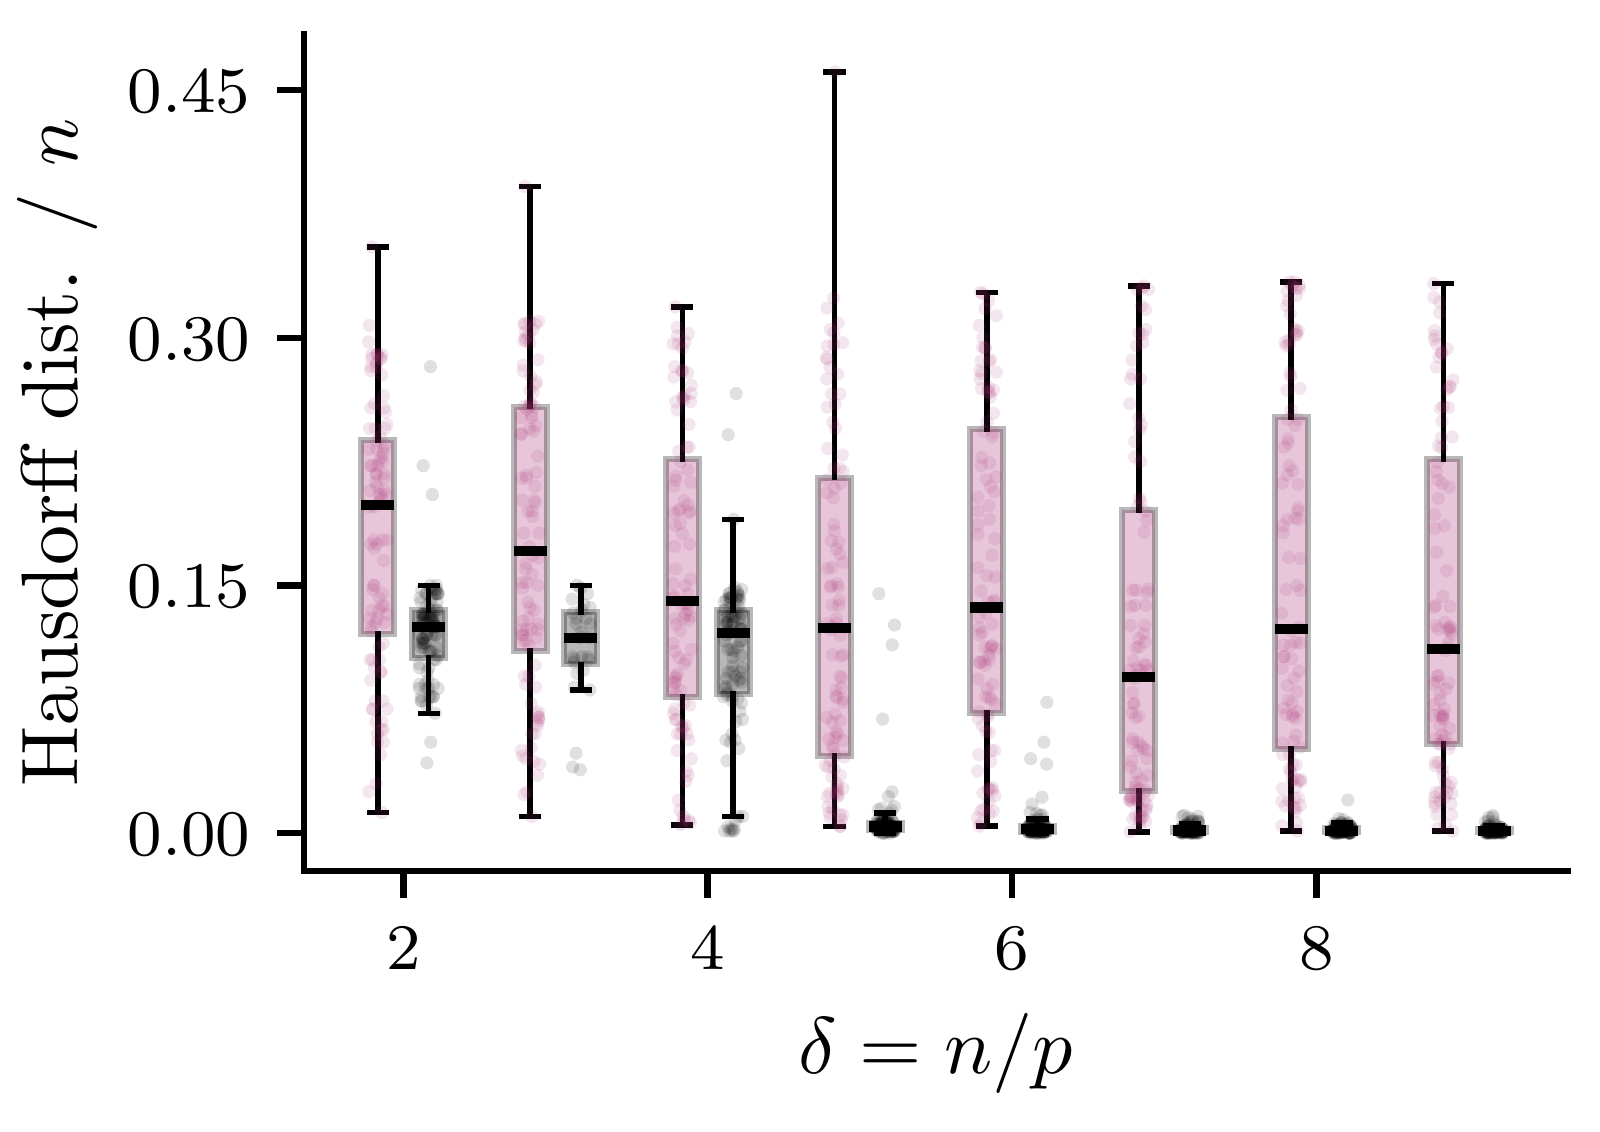

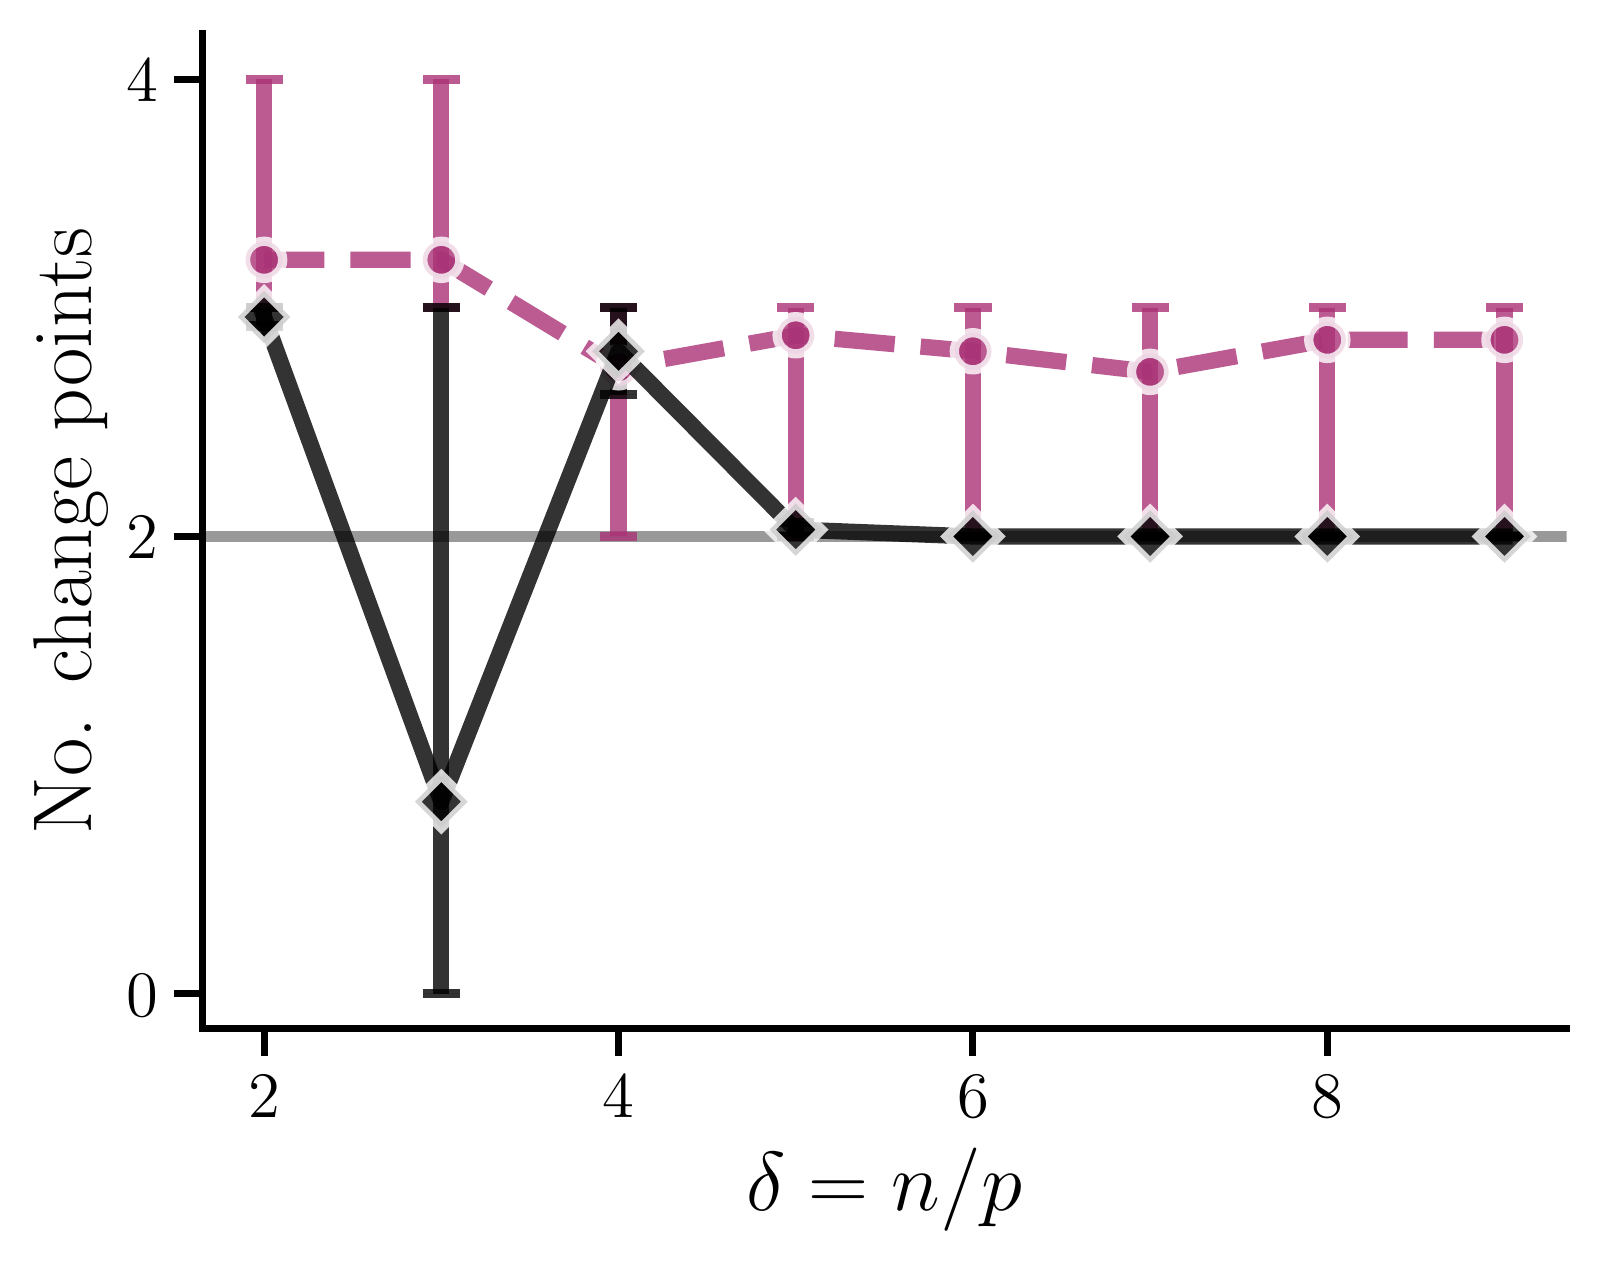

In [5]:
panels = ['figures/regenerated/M1b_dense_gaussian_ls_haus_box.pdf', 'figures/regenerated/M1b_dense_gaussian_ls_size_line.pdf'] if REGENERATE_FIGURES else ['figures/figure_11/panel_01.pdf', 'figures/figure_11/panel_02.pdf']
show_panels(panels)
